# 1 : Load Data from the FRED

In [1]:
pip install fredapi

Note: you may need to restart the kernel to use updated packages.


Impossible d’analyser la valeur spécifiée dans une clé de Registre AutoRun.


In [44]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from fredapi import Fred

In [2]:
api_key = 'ee2f9e33f36fdf884e7039bd0f313d31'
fred = Fred(api_key=api_key)

series = {"1M": "DGS1MO","3M": "DGS3MO","6M": "DGS6MO", "1Y": "DGS1",
          "5Y": "DGS5", "10Y": "DGS10", "20Y": "DGS20", "30Y": "DGS30"}
def download_data(data_series, start_date, output_file):
    
    data = pd.DataFrame()
    for maturity, series_id in data_series.items():
        data[maturity] = fred.get_series(series_id, observation_start=start_date)

    data.to_csv(output_file)

    return data

In [3]:
data = download_data(series, "2016-01-01", 'yield_curve.csv')

# 2 : Data Analysis and cleaning

In [8]:
print("Description des données : ", data.describe)

Description des données :  <bound method NDFrame.describe of               1M    3M    6M    1Y    5Y   10Y   20Y   30Y
2016-01-01   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN
2016-01-04  0.17  0.22  0.49  0.61  1.73  2.24  2.64  2.98
2016-01-05  0.20  0.20  0.49  0.68  1.73  2.25  2.67  3.01
2016-01-06  0.21  0.21  0.47  0.67  1.65  2.18  2.59  2.94
2016-01-07  0.20  0.20  0.46  0.66  1.61  2.16  2.56  2.92
...          ...   ...   ...   ...   ...   ...   ...   ...
2026-11-04  4.01  4.21  4.25  4.39  4.69  4.90  5.30  5.28
2026-11-05  4.03  4.17  4.19  4.28  4.59  4.84  5.27  5.25
2026-11-06  4.02  4.19  4.23  4.33  4.64  4.86  5.29  5.26
2026-11-09  4.04  4.24  4.26  4.38  4.67  4.88  5.29  5.26
2026-11-10  4.05  4.30  4.38  4.56  4.81  4.98  5.39  5.35

[2833 rows x 8 columns]>


In [26]:
def compute_missing_val(df):
    missing = pd.DataFrame({"Missing values": df.isna().sum(),"Missing percentage (%)": (df.isna().mean() * 100).round(2)})
    return missing 


compute_missing_val(data)

,Missing values,Missing percentage (%)
1M,118,4.17
3M,118,4.17
6M,118,4.17
1Y,118,4.17
5Y,118,4.17
10Y,118,4.17
20Y,118,4.17
30Y,118,4.17


In [41]:
def compare_missing_dates(df):
    
    missing_dates = {}
    for col in df.columns:
        missing_dates[col] = set(data.index[data[col].isna()])
    
    
    maturities = df.columns
    intersection_matrix = pd.DataFrame(index=maturities,columns=maturities, dtype=int)
    for col1 in maturities:
        for col2 in maturities:
            intersection_matrix.loc[col1, col2] = len(missing_dates[col1].intersection(missing_dates[col2]))
    print(intersection_matrix)


def identify_missing_dates(df,col) :

    missing_df_dates = df[df[col].isna()].copy()
    missing_df_dates["Day"] = missing_df_dates.index.day_name()
    missing_df_dates = missing_df_dates[missing_df_dates.index.weekday < 5] # filtration sur les jours de la semaine (lundi =0)
  
    return missing_df_dates[[col,'Day']]

compare_missing_dates(data) #Dans notre cas c'est parfait les jours qui manquent sont communs à tous.
# Maintenant il faut voir la raison de ces jours manquants, week-end ou jours fériés ? 
missing_dates = identify_missing_dates(data, '3M') #on voit que cela correspond à des jours fériés (2016-01-01, 2026-05-25)...

        1M     3M     6M     1Y     5Y    10Y    20Y    30Y
1M   118.0  118.0  118.0  118.0  118.0  118.0  118.0  118.0
3M   118.0  118.0  118.0  118.0  118.0  118.0  118.0  118.0
6M   118.0  118.0  118.0  118.0  118.0  118.0  118.0  118.0
1Y   118.0  118.0  118.0  118.0  118.0  118.0  118.0  118.0
5Y   118.0  118.0  118.0  118.0  118.0  118.0  118.0  118.0
10Y  118.0  118.0  118.0  118.0  118.0  118.0  118.0  118.0
20Y  118.0  118.0  118.0  118.0  118.0  118.0  118.0  118.0
30Y  118.0  118.0  118.0  118.0  118.0  118.0  118.0  118.0


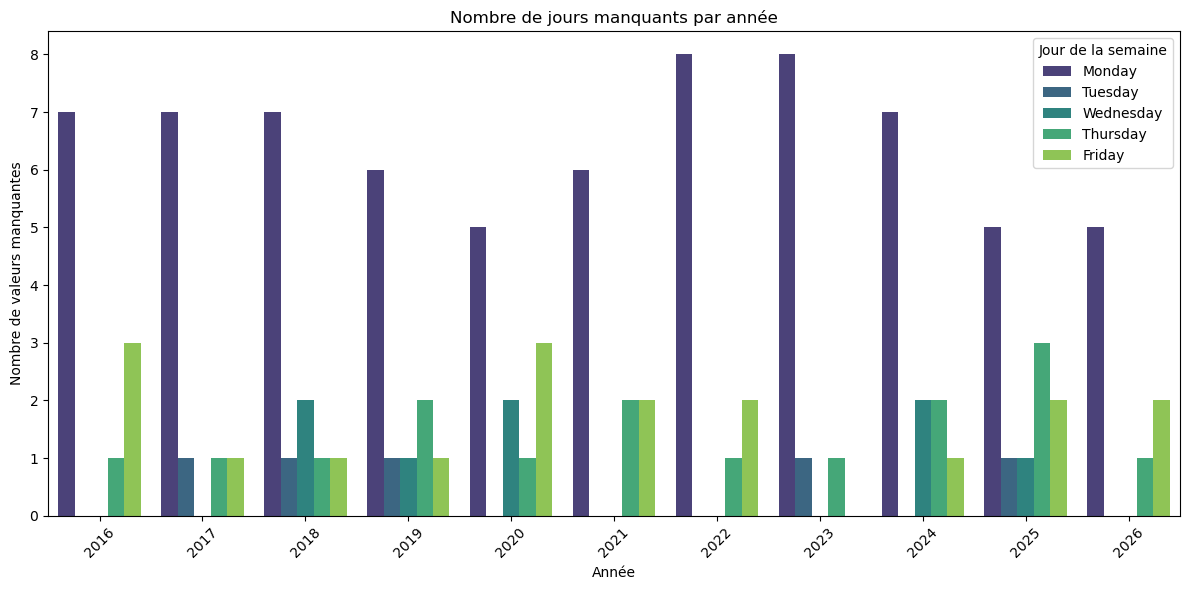

In [50]:
def hist_missing_days(df_missing) : 
    df_missing["Year"] = df_missing.index.year
    day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
    plt.figure(figsize=(12, 6))
    sns.countplot(data= df_missing, x="Year", hue="Day",order=sorted(df_missing["Year"].unique()),hue_order=day_order,palette="viridis")

    plt.title("Nombre de jours manquants par année")
    plt.xlabel("Année")
    plt.ylabel("Nombre de valeurs manquantes")
    plt.legend(title="Jour de la semaine")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    
hist_missing_days(missing_dates) # on observe une certaine stabilité 

In [56]:
# On a fait notre analyse des valeurs manquantes on peut donc les exclure sans sous du dataset
new_data = data.dropna(axis=0 , how = 'all')
print(new_data.shape)

(2715, 8)


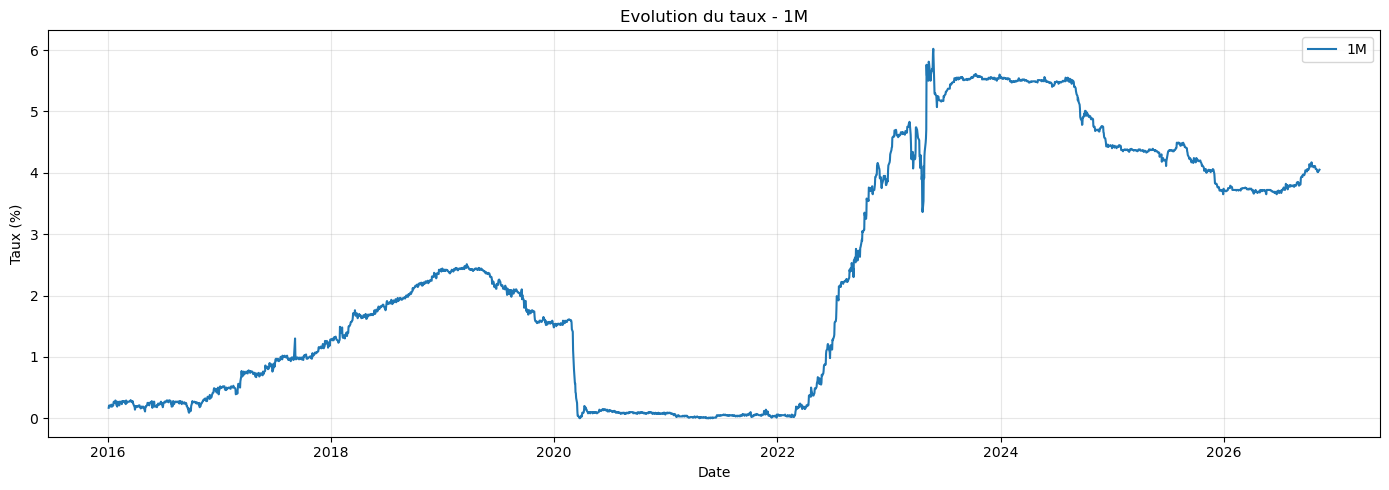

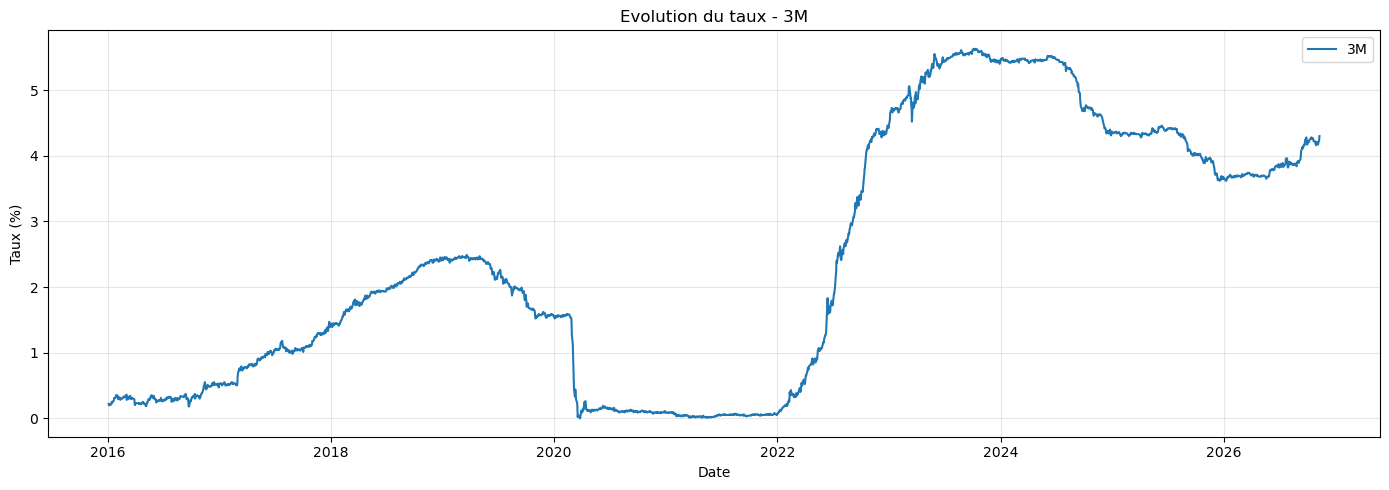

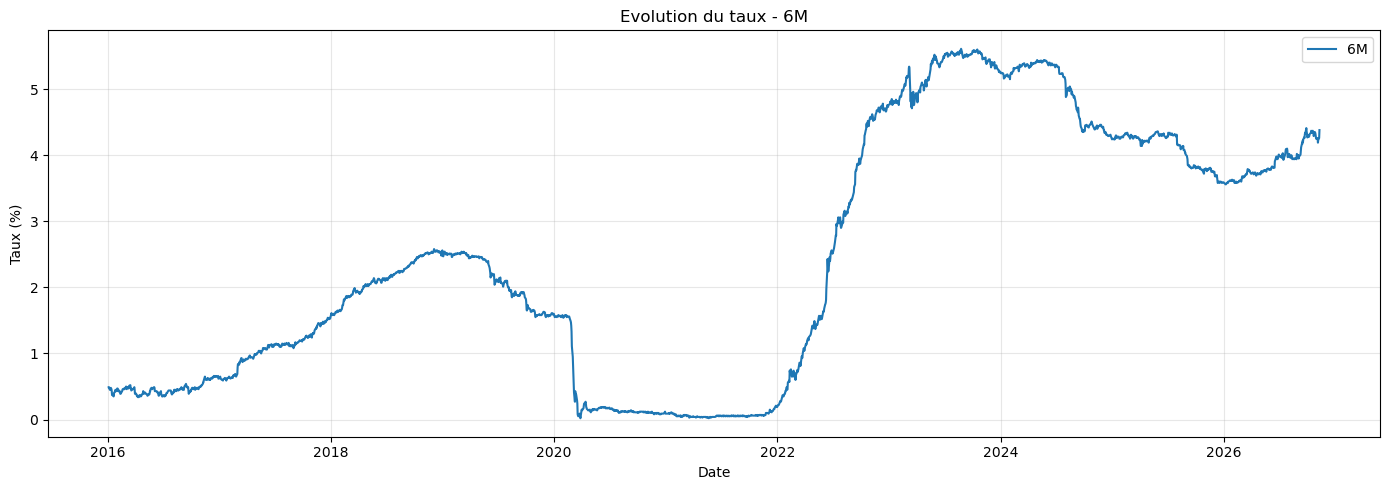

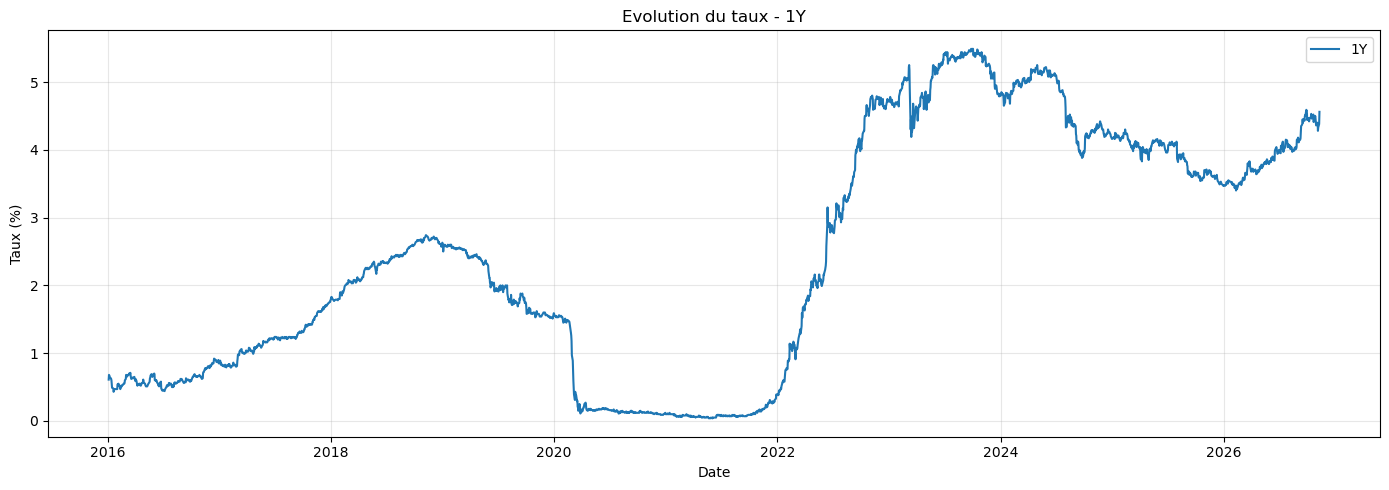

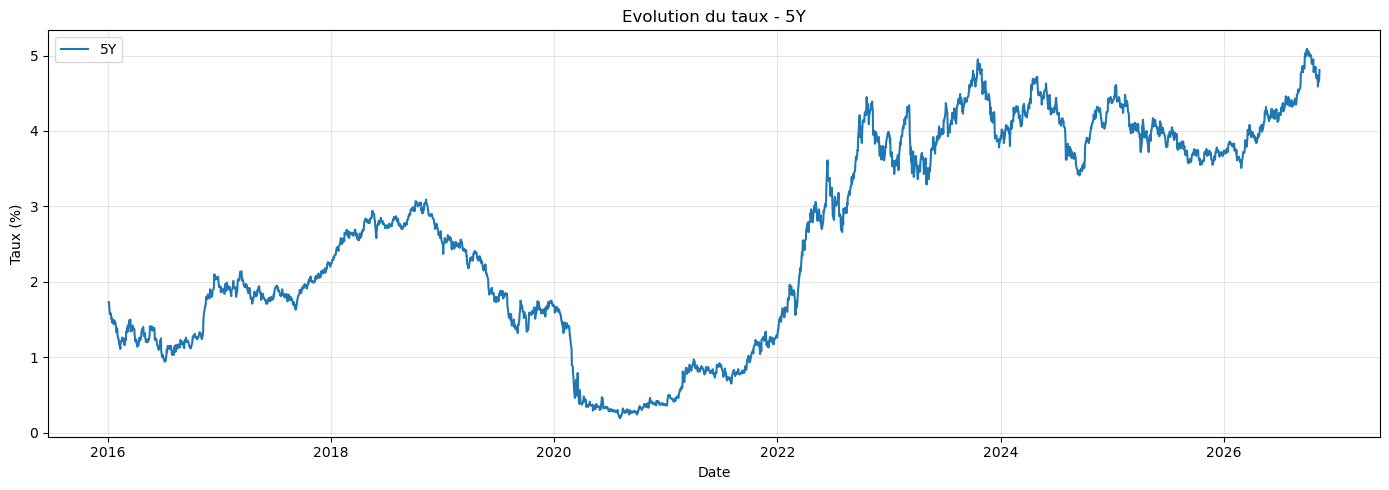

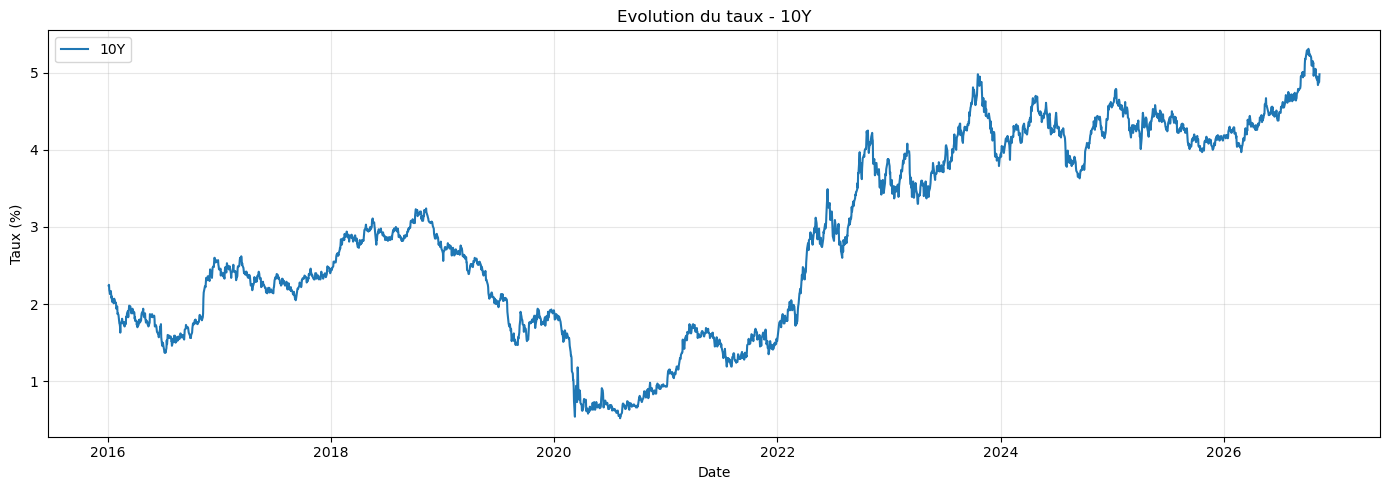

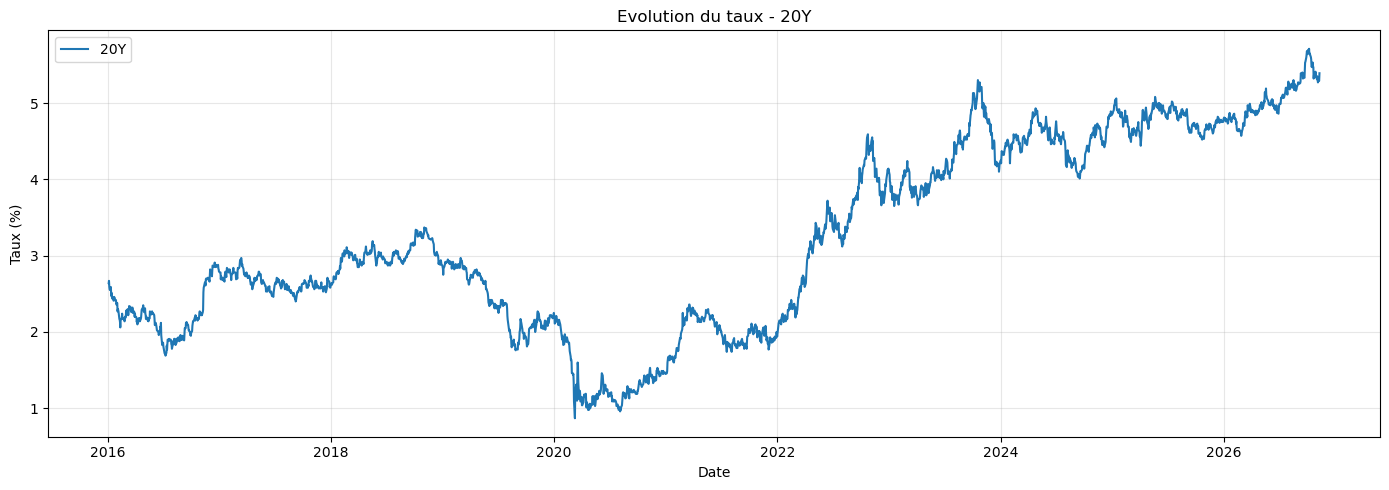

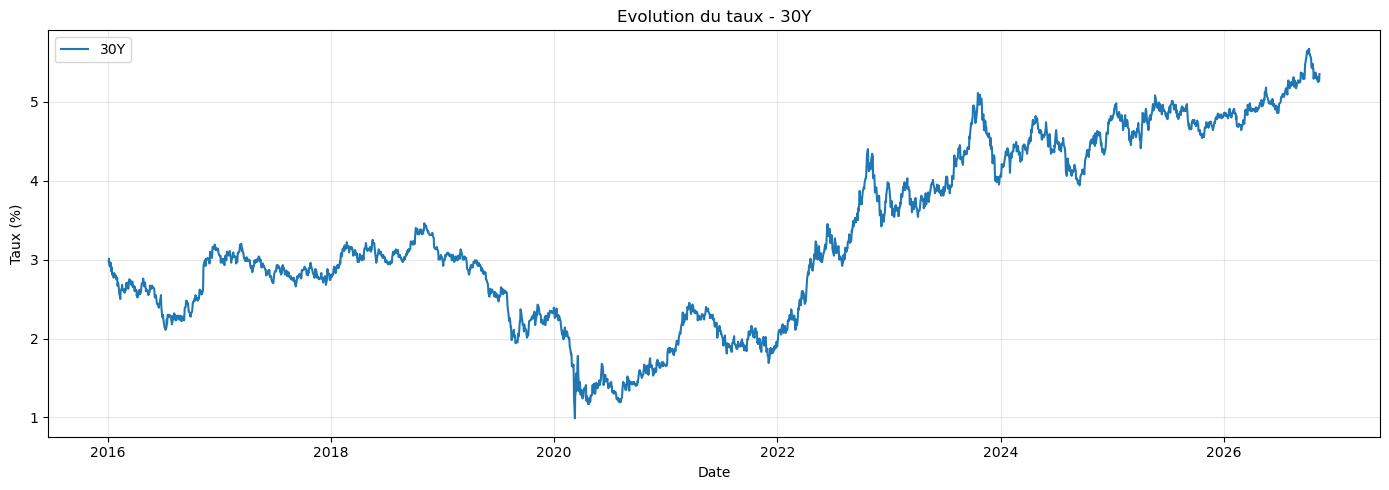

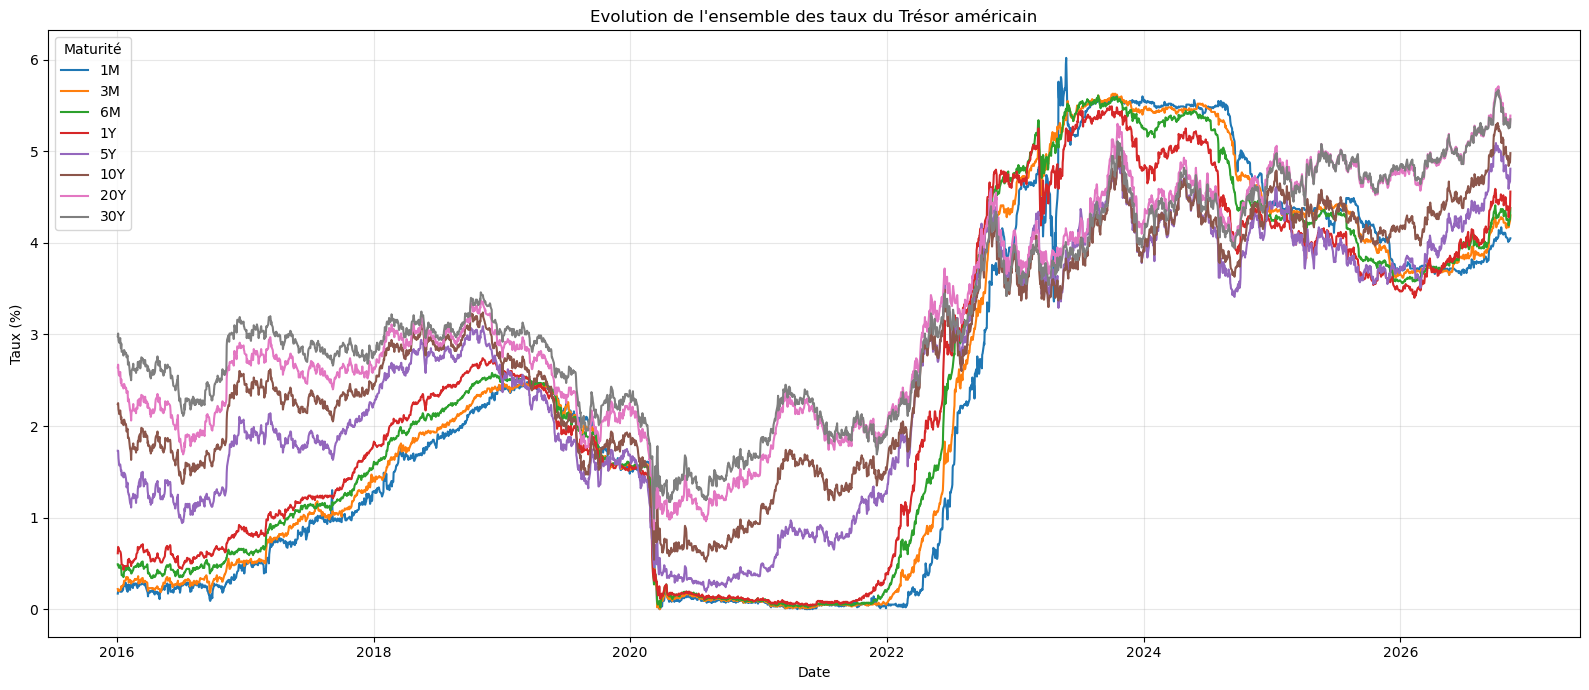

In [58]:
def plot_yield_curves(df):

    for col in df.columns:

        plt.figure(figsize=(14, 5))
        plt.plot(df.index, df[col], label=col)

        plt.title(f"Evolution du taux - {col}")
        plt.xlabel("Date")
        plt.ylabel("Taux (%)")
        plt.legend()
        plt.grid(alpha=0.3)

        plt.tight_layout()
        plt.show()

    plt.figure(figsize=(16, 7))
    for col in df.columns:
        plt.plot(df.index, df[col], label=col)

    plt.title("Evolution de l'ensemble des taux du Trésor américain")
    plt.xlabel("Date")
    plt.ylabel("Taux (%)")
    plt.legend(title="Maturité")
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_yield_curves(new_data) # le dernier graphique est intéressant car plus les matuirtés sont lointaines moins les courbes sont lisses et plus elles divergent.
# 1M, 3M, 6M sont très similaires mais les maturités plus élévées sont plus erratiques. 

In [ ]:
def plot_hist()

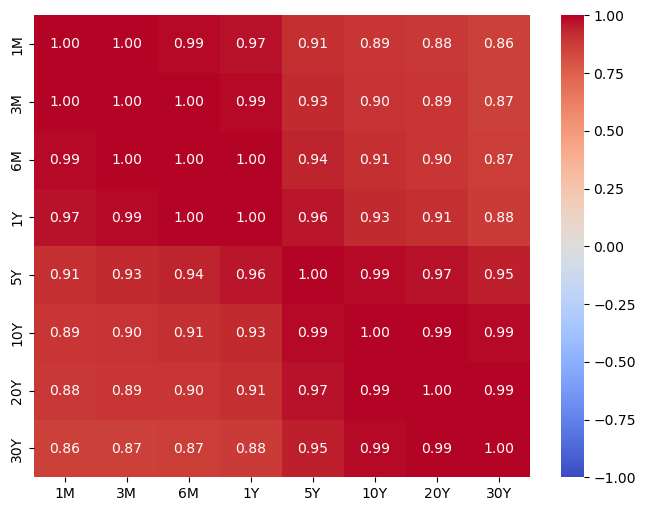

In [62]:
def heatmap(df) : 
    corr = df.select_dtypes("number").corr()
    plt.figure(figsize=(8, 6))
    sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
    plt.show()

heatmap(new_data) # Corrélations extrement fortes entre les valeurs | 2 blocs se distiguent

In [ ]:
# On va plutôt travailler avec les rendements pour des propriétes statistiques mais essayer de prédire les niveaux de taux. 

In [59]:
final_data  = new_data.diff().dropna() #Différenciation à l'ordre 1 pour plus de stationnarité
print(final_data)

              1M    3M    6M    1Y    5Y   10Y   20Y   30Y
2016-01-05  0.03 -0.02  0.00  0.07  0.00  0.01  0.03  0.03
2016-01-06  0.01  0.01 -0.02 -0.01 -0.08 -0.07 -0.08 -0.07
2016-01-07 -0.01 -0.01 -0.01 -0.01 -0.04 -0.02 -0.03 -0.02
2016-01-08  0.00  0.00 -0.01 -0.02 -0.04 -0.03 -0.01 -0.01
2016-01-11 -0.01  0.01  0.03 -0.01  0.01  0.04  0.04  0.05
...          ...   ...   ...   ...   ...   ...   ...   ...
2026-11-04 -0.02  0.00 -0.01 -0.01 -0.05 -0.05 -0.05 -0.04
2026-11-05  0.02 -0.04 -0.06 -0.11 -0.10 -0.06 -0.03 -0.03
2026-11-06 -0.01  0.02  0.04  0.05  0.05  0.02  0.02  0.01
2026-11-09  0.02  0.05  0.03  0.05  0.03  0.02  0.00  0.00
2026-11-10  0.01  0.06  0.12  0.18  0.14  0.10  0.10  0.09

[2714 rows x 8 columns]



===== 1M =====
Skewness : 3.3375
Kurtosis : 118.5083


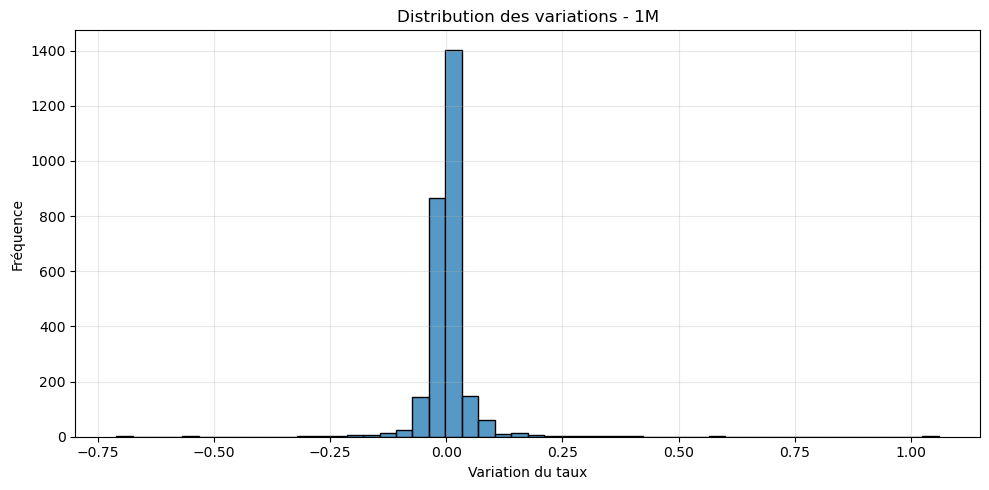


===== 3M =====
Skewness : 1.2728
Kurtosis : 19.2562


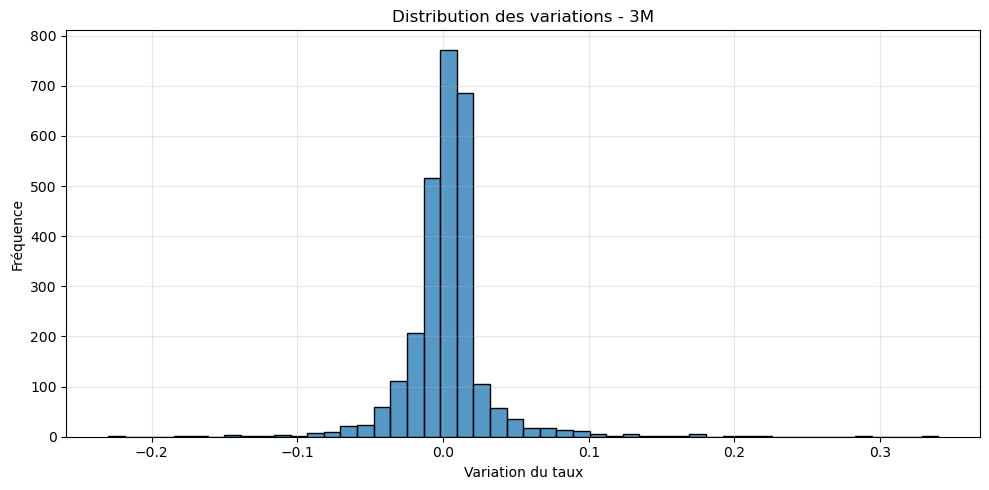


===== 6M =====
Skewness : -0.2440
Kurtosis : 18.8941


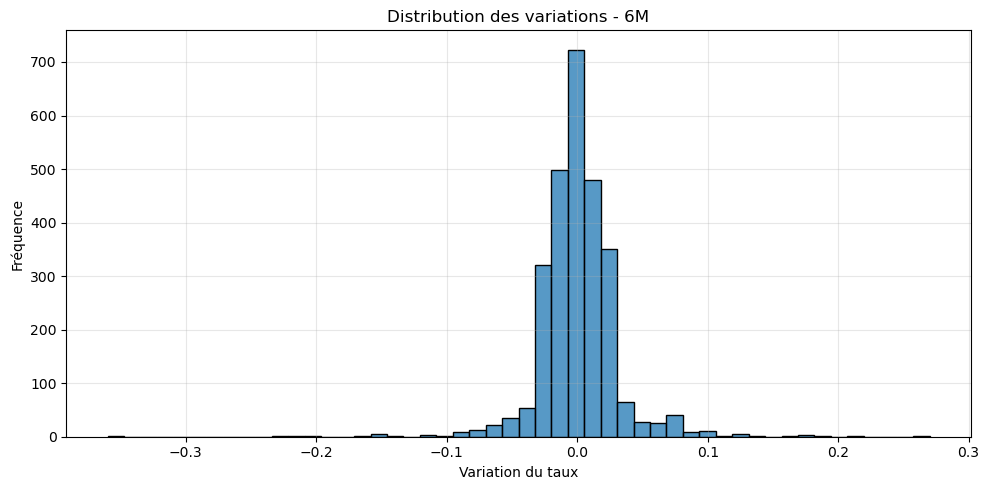


===== 1Y =====
Skewness : -0.7320
Kurtosis : 26.4376


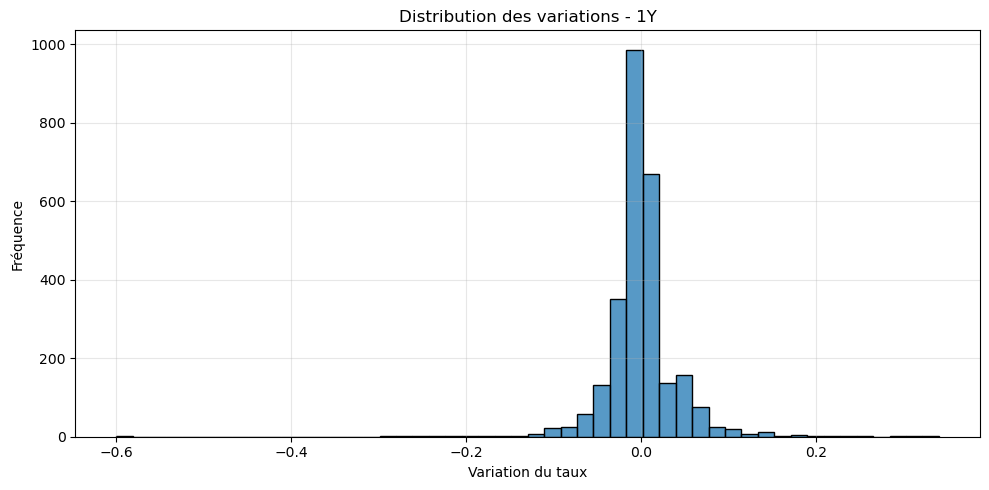


===== 5Y =====
Skewness : -0.2432
Kurtosis : 3.0502


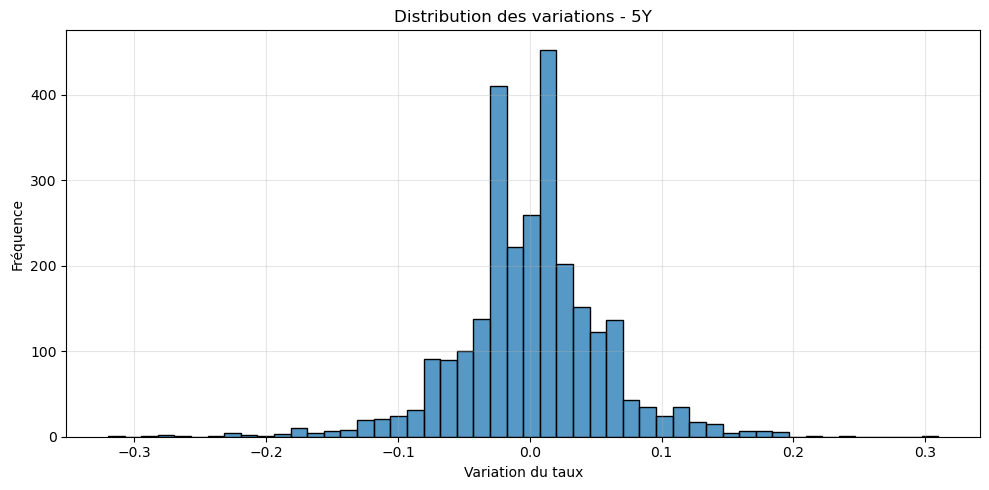


===== 10Y =====
Skewness : -0.0690
Kurtosis : 2.0417


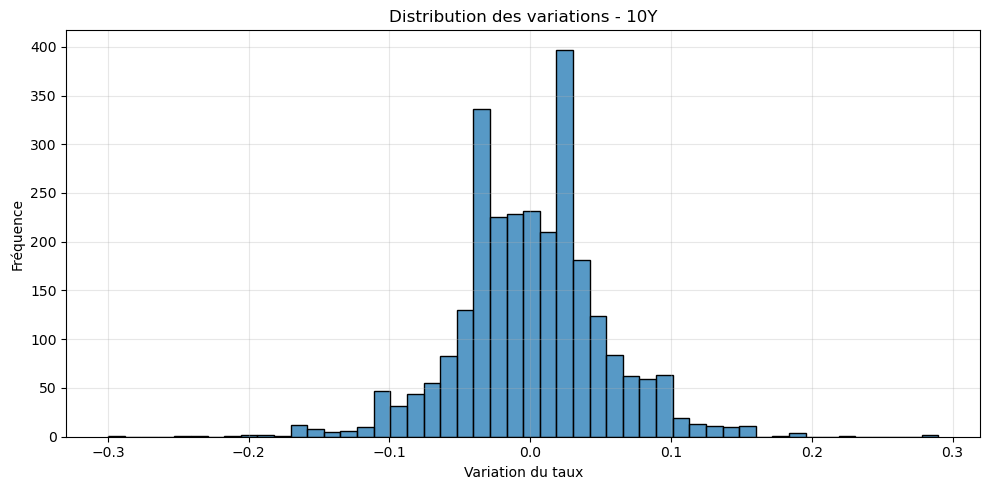


===== 20Y =====
Skewness : 0.0802
Kurtosis : 2.6004


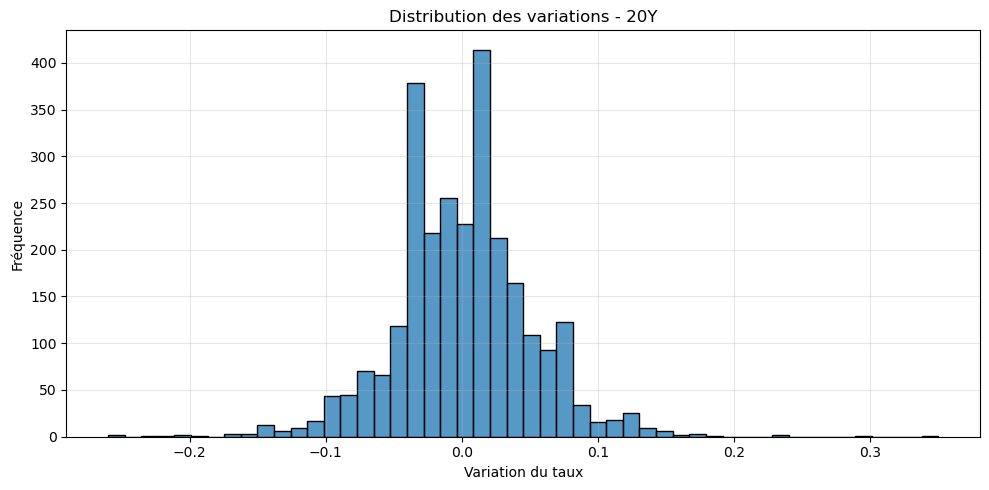


===== 30Y =====
Skewness : -0.0501
Kurtosis : 2.8059


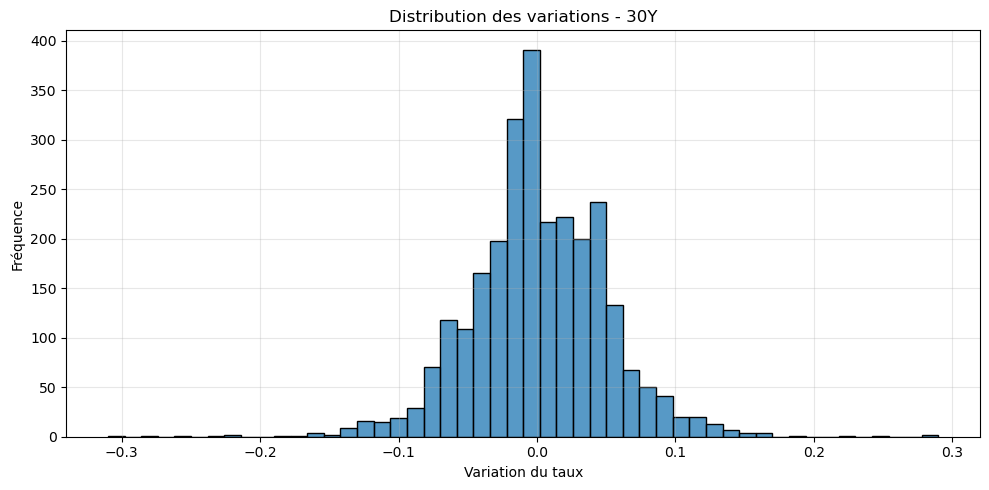

In [60]:
from scipy.stats import skew, kurtosis

def analyze_returns_distribution(df):

    for col in df.columns:

        # Calcul des statistiques
        col_data = df[col].dropna()

        skewness = skew(col_data)
        kurt = kurtosis(col_data)  # Fisher : kurtosis normale = 0

        print(f"\n===== {col} =====")
        print(f"Skewness : {skewness:.4f}")
        print(f"Kurtosis : {kurt:.4f}")

        # Histogramme
        plt.figure(figsize=(10, 5))

        sns.histplot(col_data,      bins=50,       kde=False,     stat="count" )

        plt.title(f"Distribution des variations - {col}")
        plt.xlabel("Variation du taux")
        plt.ylabel("Fréquence")
        plt.grid(alpha=0.3)

        plt.tight_layout()
        plt.show()
        
analyze_returns_distribution(final_data)
# Le kurtosis diminue fortement avec la maturité, plus celui ci est faible moins les évènments rares des queues de distribution ont des chnaces de se produire
# Skewness varie fortement selon la maturité, asymétrie vers la gauche avec l'augmentation de la maturité. 

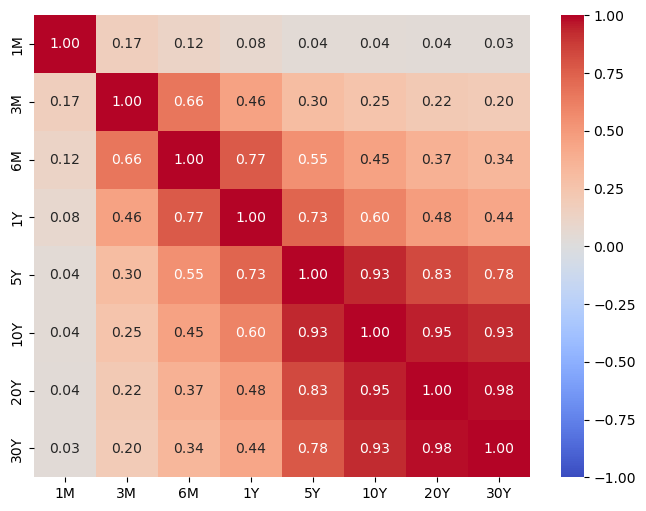

In [63]:
heatmap(final_data) # Les rendements sont bcp moins corrélés. Persistance moindre. 

In [65]:
def compute_deciles(df) : 
    deciles = df.quantile([0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1])
    return deciles

compute_deciles(final_data)    # Grosse dispersion pour les grandes maturités. Compression forte des faibles maturité (leurs taux a baissé ?)

,1M,3M,6M,1Y,5Y,10Y,20Y,30Y
0.0,-0.71,-0.23,-0.360,-0.60,-0.32,-0.30,-0.26,-0.31
0.1,-0.03,-0.02,-0.020,-0.03,-0.06,-0.06,-0.06,-0.06
0.2,-0.01,-0.01,-0.010,-0.02,-0.04,-0.04,-0.04,-0.04
0.3,-0.01,-0.01,-0.010,-0.01,-0.02,-0.02,-0.02,-0.02
0.4,0.00,0.00,0.000,0.00,-0.01,-0.01,-0.01,-0.01
0.5,0.00,0.00,0.000,0.00,0.00,0.00,0.00,0.00
0.6,0.00,0.00,0.000,0.01,0.01,0.01,0.01,0.01
0.7,0.01,0.01,0.010,0.01,0.02,0.03,0.03,0.02
0.8,0.01,0.01,0.014,0.02,0.04,0.04,0.04,0.04
0.9,0.03,0.03,0.030,0.04,0.06,0.06,0.06,0.06


# 3 : Data preprocessing

In [ ]:
# On a déjà fait du nettoyage et une différenciation à l'ordre 1. Tant qu'on n'ajoute pas de variables qualitatives ou exogènes pas de trnasformation en plus 
# Se renseigner sur le scaling ? Un adapté pour les random forest etc.... 


# 4 : Feature engineering